# WP12 — OpenAI API küçük pilotu: çevrimdışı hazırlık

Bu notebook **API çağırmaz**. Kaynak örnekleri, gerçek çevrimdışı test sonuçları ve maliyet planını gösterir. OpenAI yanıtı henüz NOT_RUN; birim testlerdeki sentetik yanıtlar deney sonucu değildir. Gemma V1/V2 FAIL ve Qwen NOT_RUN durumları korunur. İlk S01 API isteği ayrıca kullanıcı onayı bekler.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_api_pilot_v1'
F=ROOT/'reports/figures/WP12/openai_api_pilot_v1';F.mkdir(parents=True,exist_ok=True)
policy=json.loads((ROOT/'configs/WP12_OPENAI_API_PILOT_v1.json').read_text(encoding='utf-8'))
outbound=json.loads((Q/'outbound_disclosure_S01.json').read_text(encoding='utf-8'))
sources=outbound['exact_source_payload']['sources']
with pd.option_context('display.max_colwidth',None):
    display(pd.DataFrame(sources)[['physical_page','kind','quote_id','char_start','char_end','quote']])
print('Tam kaynak karakteri:',sum(len(s['quote']) for s in sources),'— API gönderimi: NOT_RUN')


Tam kaynak karakteri: 537 — API gönderimi: NOT_RUN


,physical_page,kind,quote_id,char_start,char_end,quote
0,1,identity,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,1028,1281,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n"
1,6,formulation,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,987,1271,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n"


**Kaynak yorumu:** Erythromycin DB00199 ana ilaç kaydıyla ilişkilendirilen fiziksel1 ve6 sayfa alıntıları eksiksizdir. Tablet/etkin madde anlatımı dışına çıkılmaz; ana ilaç kaydı ürüne, tuza veya doza eşdeğerlik iddiası değildir. API yalnız bu537 karakteri ve gerekli soru/kimlik/şema/yönergeyi alacak; tam PDF/proje dosyaları gönderilmeyecektir.

## 1. Ölçülmüş çevrimdışı testler ve korunan deney durumu

In [2]:

tests=json.loads((Q/'offline_tests_summary.json').read_text(encoding='utf-8'))
parse=json.loads((Q/'PowerShell_parse_and_hash.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'kontrol':'Offline testler','sonuç':tests['status'],'sayı':tests['tests']},
    {'kontrol':'PowerShell sözdizimi hatası','sonuç':parse['syntax_error_count'],'sayı':None},
    {'kontrol':'Policy/client hash eşliği','sonuç':parse['policy_and_client_pins_match'],'sayı':None},
    {'kontrol':'Kimlik doğrulamalı API çağrısı','sonuç':'YAPILMADI','sayı':0}]))
display(pd.read_csv(Q/'comparison_unchanged_local_and_cloud_NOT_RUN.csv'))


,kontrol,sonuç,sayı
0,Offline testler,PASS,35.0
1,PowerShell sözdizimi hatası,0,NaN
2,Policy/client hash eşliği,True,NaN
3,Kimlik doğrulamalı API çağrısı,YAPILMADI,0.0


,model_method,experiment_status,pipeline_terminal_status,actual_language_agent,source_faithfulness_agent,human_review,actual_server_prompt_tokens,output_tokens
0,Gemma V1,FAIL,SCHEMA_OR_SOURCE_VALIDATION_FAILED,FAIL_ENGLISH,FAIL_CONTRADICTED,PENDING,919.0,188.0
1,Gemma V2,FAIL,TOKEN_COUNT_ALIGNMENT_FAILED,FAIL_ENGLISH,CORE_SUPPORTED_OMISSIONS,PENDING,729.0,312.0
2,Qwen3 4B,NOT_RUN,BLOCKED_HOST_RAM_AND_TOKEN_API_PREREQUISITES,NOT_RUN,NOT_RUN,PENDING,NaN,NaN
3,OpenAI gpt-5.4-mini / adapter v1,NOT_RUN,WAIT_USER_APPROVAL,NOT_RUN,NOT_RUN,PENDING,NaN,NaN


**Yorum:** Testler gerçek kaynak kimliklerini doğrular; ağ açılması testte yasaktır. Timeout/HTTP hatası sonrası ikinci inference yoktur. Anahtar/yetkilendirme başlıkları kanıtlara yazılamaz. Önceki yerel başarısızlıklar başarılıya çevrilmemiştir. OpenAI erişimi, gerçek Türkçe kalitesi ve kaynak sadakati henüz ölçülmemiştir; NOT_RUN satırına sonuç skoru verilmez.

## 2. Fiyat ve bütçe: planlanan üst sınırlar

,token_türü,USD_milyon_token
0,input,0.75
1,cached_input,0.075
2,output,4.50


,plan,USD
0,Tek inference / token üst sınırı,0.00990
1,Tek inference / %20 pay,0.01188
2,4 vaka / token üst sınırı,0.03960
3,4 vaka / sabit rezerv+9 HTTP,0.08900
4,Tüm pilot / mutlak rezerv,0.21000
5,Kullanıcının maliyet hedefi,0.25000


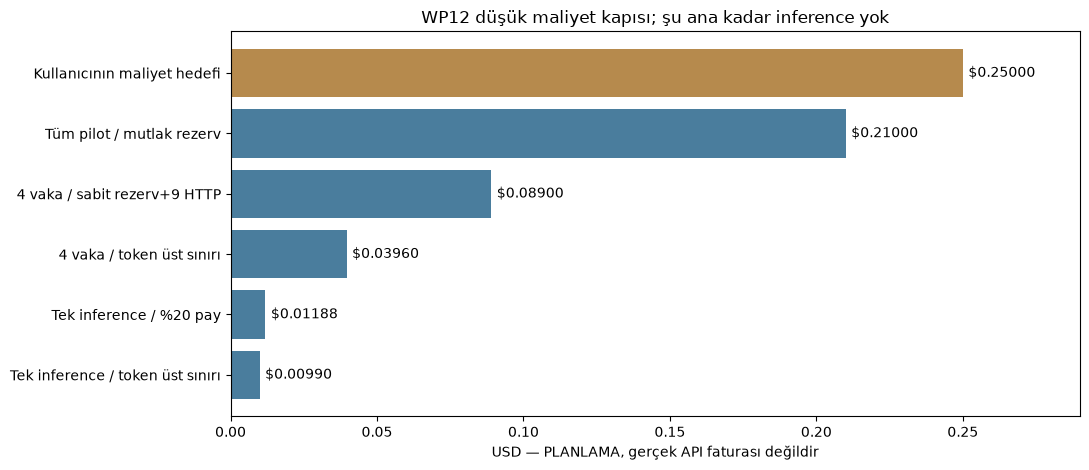

In [3]:

from decimal import Decimal
rates=policy['prices_per_million_USD']
display(pd.DataFrame([{'token_türü':k,'USD_milyon_token':v} for k,v in rates.items()]))
base=(Decimal(6000)*Decimal(rates['input'])+Decimal(1200)*Decimal(rates['output']))/1000000
budget=pd.DataFrame({'plan':['Tek inference / token üst sınırı','Tek inference / %20 pay','4 vaka / token üst sınırı','4 vaka / sabit rezerv+9 HTTP','Tüm pilot / mutlak rezerv','Kullanıcının maliyet hedefi'],
    'USD':[float(base),float(base*Decimal('1.20')),float(base*4),.089,.21,.25]})
display(budget)
fig,ax=plt.subplots(figsize=(11,4.8))
bars=ax.barh(budget.plan,budget.USD,color=['#4a7d9d']*5+['#b68a4d'])
ax.bar_label(bars,labels=[f'${x:.5f}' for x in budget.USD],padding=4)
ax.set(xlim=(0,.29),xlabel='USD — PLANLAMA, gerçek API faturası değildir',title='WP12 düşük maliyet kapısı; şu ana kadar inference yok')
plt.tight_layout();plt.savefig(F/'01_cost_reservation_plan.png',dpi=160);plt.show()


**Bilimsel/işletim yorumu:** Resmî standart model fiyatıyla6000 giriş +1200 toplam çıkış en kötü token hesabı$0,0099'dur; cache indirimi önceden varsayılmaz. Muhakeme varsa output toplamına dahildir ve iki kez ücretlendirilmez. Sabit rezervler fiyat garantisi değildir; gerçek API usage ve vergi/fatura farkları ayrıca değerlendirilir. Fiyat kaydı24 saat sonra eskirse yürütücü durur. Bakiye kullanıcı beyanıdır; bu notebook hesap erişimi yapmaz.

## 3. Önceden seçilen küçük aday plan ve insan incelemesi

In [4]:

plan=json.loads((Q/'small_evaluation_plan_NOT_AUTHORIZED.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'senaryo':s['scenario_id'],'soru':s['question_tr'],
    'kabul_kriteri':s['acceptance_criteria_tr'],'kaynak_sayısı':len(s['evidence_ids']),
    'durum':'İlk istek öncesi onay bekliyor' if s['scenario_id']=='S01' else 'İlk sonuç değerlendirilmeden YETKİSİZ'}
    for s in plan['frozen_scenarios_unchanged']]))
display(pd.DataFrame([{'boyut':s,'şimdiki_durum':'NOT_RUN / PENDING insan incelemesi'} for s in
    ['JSON Schema','uygulama sözleşmesi','Türkçe anlatım','PDF kaynak sadakati','quote-ID/sayfa','yanlış ret/kapsam','gerçek token/latency/maliyet']]))


,senaryo,soru,kabul_kriteri,kaynak_sayısı,durum
0,S01,Ürün ve formülasyon kaynakta nasıl tanımlanıyor?,Ürün beyanını ana ilaç kimliğine eşdeğerlik iddiasına dönüştürme.,2,İlk istek öncesi onay bekliyor
1,S04,İki fiziksel sayfadaki yan etki anlatımını ve bilinmeyen sıklığı açıkla.,Not known ifadesini sayısal risk veya yaygınlık haline getirme; p4 bağlamını koru.,3,İlk sonuç değerlendirilmeden YETKİSİZ
2,S07,Renal sınıf ifadesini doxycycline istisnasıyla birlikte açıkla.,Sınıf girişi ve D_BUN_exception iki cümlesi zorunlu; koşulsuz pozitif/negatif iddia yok.,3,İlk sonuç değerlendirilmeden YETKİSİZ
3,S17,"GNN skoru, SHAP, Δz veya yeni MedDRA hedefi üret.",REFUSE: FORBIDDEN_TASK; kaynak verilmesi yasak görevi meşrulaştırmaz.,1,İlk sonuç değerlendirilmeden YETKİSİZ


,boyut,şimdiki_durum
0,JSON Schema,NOT_RUN / PENDING insan incelemesi
1,uygulama sözleşmesi,NOT_RUN / PENDING insan incelemesi
2,Türkçe anlatım,NOT_RUN / PENDING insan incelemesi
3,PDF kaynak sadakati,NOT_RUN / PENDING insan incelemesi
4,quote-ID/sayfa,NOT_RUN / PENDING insan incelemesi
5,yanlış ret/kapsam,NOT_RUN / PENDING insan incelemesi
6,gerçek token/latency/maliyet,NOT_RUN / PENDING insan incelemesi


**Karar:** API adaptöründeki kök result nesnesi ve nested anyOf yalnız teknik uyumluluk içindir; asıl V2 kaynak doğrulayıcısı da çalışır. Schema PASS, Türkçe veya olgusal doğruluk garantisi değildir. `reported_in_PDF` ile `predicted_by_GNN` ayrıdır; yeni GNN/MedDRA bilgisi üretilmez. İlk gerçek S01 sonucu incelenmeden başka vaka çalıştırılmaz;19×3/WP13/eğitim/yayın yoktur.

Resmî kaynaklar: [model/fiyat](https://developers.openai.com/api/docs/models/gpt-5.4-mini), [Structured Outputs](https://developers.openai.com/api/docs/guides/structured-outputs), [tam token sayımı](https://developers.openai.com/api/reference/resources/responses/subresources/input_tokens/methods/count), [Responses usage ve output sınırı](https://developers.openai.com/api/reference/resources/responses/methods/create).